In [3]:
import pandas as pd 
import matplotlib.pyplot as plt 


transactions = pd.read_csv(f"data/QVI_transaction_data.csv")
customers = pd.read_csv(f"data/QVI_purchase_behaviour.csv")

In [4]:
transactions

,DATE,STORE_NBR,LYLTY_CARD_NBR,TXN_ID,PROD_NBR,PROD_NAME,PROD_QTY,TOT_SALES
0,43390,1,1000,1,5,Natural Chip Compny SeaSalt175g,2,6.0
1,43599,1,1307,348,66,CCs Nacho Cheese 175g,3,6.3
2,43605,1,1343,383,61,Smiths Crinkle Cut Chips Chicken 170g,2,2.9
3,43329,2,2373,974,69,Smiths Chip Thinly S/Cream&Onion 175g,5,15.0
4,43330,2,2426,1038,108,Kettle Tortilla ChpsHny&Jlpno Chili 150g,3,13.8
...,...,...,...,...,...,...,...,...
264831,43533,272,272319,270088,89,Kettle Sweet Chilli And Sour Cream 175g,2,10.8
264832,43325,272,272358,270154,74,Tostitos Splash Of Lime 175g,1,4.4
264833,43410,272,272379,270187,51,Doritos Mexicana 170g,2,8.8
264834,43461,272,272379,270188,42,Doritos Corn Chip Mexican Jalapeno 150g,2,7.8


In [5]:
customers 

,LYLTY_CARD_NBR,LIFESTAGE,PREMIUM_CUSTOMER
0,1000,YOUNG SINGLES/COUPLES,Premium
1,1002,YOUNG SINGLES/COUPLES,Mainstream
2,1003,YOUNG FAMILIES,Budget
3,1004,OLDER SINGLES/COUPLES,Mainstream
4,1005,MIDAGE SINGLES/COUPLES,Mainstream
...,...,...,...
72632,2370651,MIDAGE SINGLES/COUPLES,Mainstream
72633,2370701,YOUNG FAMILIES,Mainstream
72634,2370751,YOUNG FAMILIES,Premium
72635,2370961,OLDER FAMILIES,Budget


In [6]:
print(f"Transactions null:\n\n{transactions.isnull().sum()}\n")
print(f"Transactions null:\n\n{customers.isnull().sum()}")

Transactions null:

DATE              0
STORE_NBR         0
LYLTY_CARD_NBR    0
TXN_ID            0
PROD_NBR          0
PROD_NAME         0
PROD_QTY          0
TOT_SALES         0
dtype: int64

Transactions null:

LYLTY_CARD_NBR      0
LIFESTAGE           0
PREMIUM_CUSTOMER    0
dtype: int64


In [7]:
print(f"Transactions na:\n\n{transactions.isna().sum()}\n")
print(f"Transactions na:\n\n{customers.isna().sum()}")

Transactions na:

DATE              0
STORE_NBR         0
LYLTY_CARD_NBR    0
TXN_ID            0
PROD_NBR          0
PROD_NAME         0
PROD_QTY          0
TOT_SALES         0
dtype: int64

Transactions na:

LYLTY_CARD_NBR      0
LIFESTAGE           0
PREMIUM_CUSTOMER    0
dtype: int64


In [8]:
transactions.info()

<class 'pandas.DataFrame'>
RangeIndex: 264836 entries, 0 to 264835
Data columns (total 8 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   DATE            264836 non-null  int64  
 1   STORE_NBR       264836 non-null  int64  
 2   LYLTY_CARD_NBR  264836 non-null  int64  
 3   TXN_ID          264836 non-null  int64  
 4   PROD_NBR        264836 non-null  int64  
 5   PROD_NAME       264836 non-null  str    
 6   PROD_QTY        264836 non-null  int64  
 7   TOT_SALES       264836 non-null  float64
dtypes: float64(1), int64(6), str(1)
memory usage: 24.6 MB


In [9]:
transactions.describe()

,DATE,STORE_NBR,LYLTY_CARD_NBR,TXN_ID,PROD_NBR,PROD_QTY,TOT_SALES
count,264836.000000,264836.00000,2.648360e+05,2.648360e+05,264836.000000,264836.000000,264836.000000
mean,43464.036260,135.08011,1.355495e+05,1.351583e+05,56.583157,1.907309,7.304200
std,105.389282,76.78418,8.057998e+04,7.813303e+04,32.826638,0.643654,3.083226
min,43282.000000,1.00000,1.000000e+03,1.000000e+00,1.000000,1.000000,1.500000
25%,43373.000000,70.00000,7.002100e+04,6.760150e+04,28.000000,2.000000,5.400000
50%,43464.000000,130.00000,1.303575e+05,1.351375e+05,56.000000,2.000000,7.400000
75%,43555.000000,203.00000,2.030942e+05,2.027012e+05,85.000000,2.000000,9.200000
max,43646.000000,272.00000,2.373711e+06,2.415841e+06,114.000000,200.000000,650.000000


In [10]:
customers.info()

<class 'pandas.DataFrame'>
RangeIndex: 72637 entries, 0 to 72636
Data columns (total 3 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   LYLTY_CARD_NBR    72637 non-null  int64
 1   LIFESTAGE         72637 non-null  str  
 2   PREMIUM_CUSTOMER  72637 non-null  str  
dtypes: int64(1), str(2)
memory usage: 3.3 MB


In [11]:
customers.describe()

,LYLTY_CARD_NBR
count,7.263700e+04
mean,1.361859e+05
std,8.989293e+04
min,1.000000e+03
25%,6.620200e+04
50%,1.340400e+05
75%,2.033750e+05
max,2.373711e+06


In [12]:
transactions['DATE'] = pd.to_datetime(transactions['DATE'])

In [13]:
data = pd.merge(transactions, customers, on="LYLTY_CARD_NBR")

In [14]:
data

,DATE,STORE_NBR,LYLTY_CARD_NBR,TXN_ID,PROD_NBR,PROD_NAME,PROD_QTY,TOT_SALES,LIFESTAGE,PREMIUM_CUSTOMER
0,1970-01-01 00:00:00.000043390,1,1000,1,5,Natural Chip Compny SeaSalt175g,2,6.0,YOUNG SINGLES/COUPLES,Premium
1,1970-01-01 00:00:00.000043599,1,1307,348,66,CCs Nacho Cheese 175g,3,6.3,MIDAGE SINGLES/COUPLES,Budget
2,1970-01-01 00:00:00.000043605,1,1343,383,61,Smiths Crinkle Cut Chips Chicken 170g,2,2.9,MIDAGE SINGLES/COUPLES,Budget
3,1970-01-01 00:00:00.000043329,2,2373,974,69,Smiths Chip Thinly S/Cream&Onion 175g,5,15.0,MIDAGE SINGLES/COUPLES,Budget
4,1970-01-01 00:00:00.000043330,2,2426,1038,108,Kettle Tortilla ChpsHny&Jlpno Chili 150g,3,13.8,MIDAGE SINGLES/COUPLES,Budget
...,...,...,...,...,...,...,...,...,...,...
264831,1970-01-01 00:00:00.000043533,272,272319,270088,89,Kettle Sweet Chilli And Sour Cream 175g,2,10.8,YOUNG SINGLES/COUPLES,Premium
264832,1970-01-01 00:00:00.000043325,272,272358,270154,74,Tostitos Splash Of Lime 175g,1,4.4,YOUNG SINGLES/COUPLES,Premium
264833,1970-01-01 00:00:00.000043410,272,272379,270187,51,Doritos Mexicana 170g,2,8.8,YOUNG SINGLES/COUPLES,Premium
264834,1970-01-01 00:00:00.000043461,272,272379,270188,42,Doritos Corn Chip Mexican Jalapeno 150g,2,7.8,YOUNG SINGLES/COUPLES,Premium


In [15]:
data.groupby("LIFESTAGE")["TOT_SALES"].sum().sort_values(ascending=False)

LIFESTAGE
OLDER SINGLES/COUPLES     402426.75
RETIREES                  366470.90
OLDER FAMILIES            353767.20
YOUNG FAMILIES            316160.10
YOUNG SINGLES/COUPLES     260405.30
MIDAGE SINGLES/COUPLES    184751.30
NEW FAMILIES               50433.45
Name: TOT_SALES, dtype: float64

In [16]:
data.groupby("PREMIUM_CUSTOMER")["TOT_SALES"].sum().sort_values(ascending=False)

PREMIUM_CUSTOMER
Mainstream    750744.50
Budget        676211.55
Premium       507458.95
Name: TOT_SALES, dtype: float64

In [17]:
data.groupby("LIFESTAGE")["TOT_SALES"].mean().sort_values()

LIFESTAGE
YOUNG SINGLES/COUPLES     7.158515
YOUNG FAMILIES            7.252709
OLDER FAMILIES            7.279760
NEW FAMILIES              7.289124
MIDAGE SINGLES/COUPLES    7.357678
RETIREES                  7.364325
OLDER SINGLES/COUPLES     7.386823
Name: TOT_SALES, dtype: float64

In [18]:
data.groupby("LIFESTAGE")["LYLTY_CARD_NBR"].count()

LIFESTAGE
MIDAGE SINGLES/COUPLES    25110
NEW FAMILIES               6919
OLDER FAMILIES            48596
OLDER SINGLES/COUPLES     54479
RETIREES                  49763
YOUNG FAMILIES            43592
YOUNG SINGLES/COUPLES     36377
Name: LYLTY_CARD_NBR, dtype: int64

In [19]:
data.groupby("LYLTY_CARD_NBR")["TOT_SALES"].mean().max

<bound method Series.max of LYLTY_CARD_NBR
1000        6.0
1002        2.7
1003        3.3
1004        1.9
1005        2.8
           ... 
2370651    13.0
2370701     7.2
2370751     9.2
2370961     9.3
2373711    11.4
Name: TOT_SALES, Length: 72637, dtype: float64>

In [20]:
summary = data.groupby("LIFESTAGE")["TOT_SALES"].agg(["sum","mean","count"])
print(summary)

                              sum      mean  count
LIFESTAGE                                         
MIDAGE SINGLES/COUPLES  184751.30  7.357678  25110
NEW FAMILIES             50433.45  7.289124   6919
OLDER FAMILIES          353767.20  7.279760  48596
OLDER SINGLES/COUPLES   402426.75  7.386823  54479
RETIREES                366470.90  7.364325  49763
YOUNG FAMILIES          316160.10  7.252709  43592
YOUNG SINGLES/COUPLES   260405.30  7.158515  36377


C:\Users\Pc\AppData\Local\Temp\ipykernel_28424\3149209764.py:15: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(summary.index, rotation=50, ha="right")


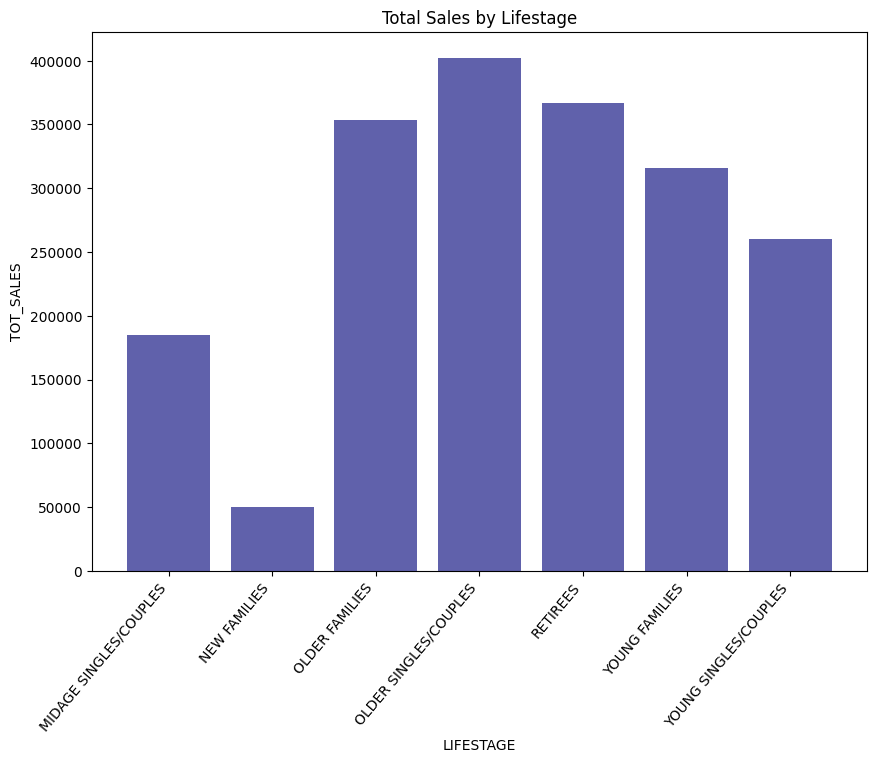

In [32]:
fig, ax = plt.subplots(figsize=(10,7))


ax.bar(summary.index, summary["sum"], color="#6061ab")


ax.set_title("Total Sales by Lifestage")
ax.set_xlabel("LIFESTAGE")
ax.set_ylabel("TOT_SALES")


ax.set_xticklabels(summary.index, rotation=50, ha="right")


fig.savefig(r"images/Total Sales by Lifestage.png", dpi=300, bbox_inches="tight")


plt.show()

C:\Users\Pc\AppData\Local\Temp\ipykernel_28424\914424129.py:11: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(summary.index, rotation=50, ha="right")


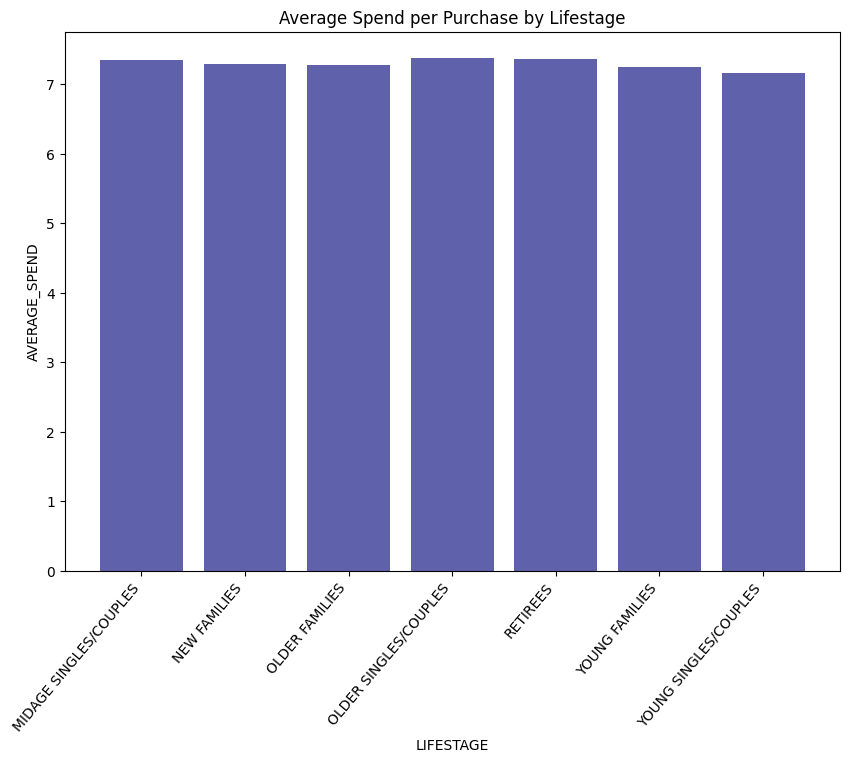

In [34]:
fig,ax = plt.subplots(figsize=(10,7))

ax.bar(summary.index, summary["mean"], color="#6061ab")


ax.set_title("Average Spend per Purchase by Lifestage")
ax.set_xlabel("LIFESTAGE")
ax.set_ylabel("AVERAGE_SPEND")


ax.set_xticklabels(summary.index, rotation=50, ha="right")


fig.savefig(r"images/Average Spend per Purchase by Lifestage.png", dpi=300, bbox_inches="tight")


plt.show()

C:\Users\Pc\AppData\Local\Temp\ipykernel_28424\3118924873.py:6: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(summary.index, rotation=50, ha="right")


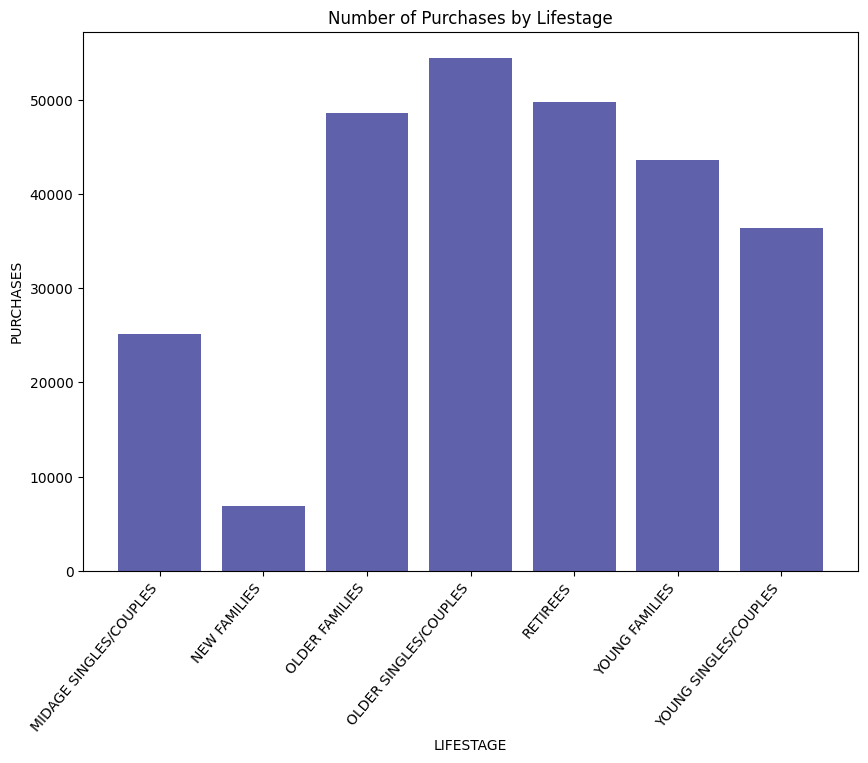

In [36]:
fig,ax =plt.subplots(figsize=(10,7))
ax.bar(summary.index,summary["count"],color="#6061ab")
ax.set_title("Number of Purchases by Lifestage")
ax.set_xlabel("LIFESTAGE")
ax.set_ylabel("PURCHASES")
ax.set_xticklabels(summary.index, rotation=50, ha="right")

fig.savefig(r"images/Number of Purchases by Lifestage.png", dpi=300, bbox_inches="tight")


plt.show()

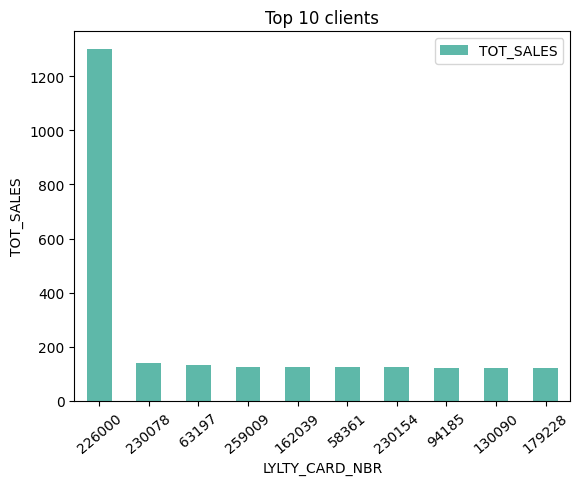

In [37]:
top_clients = data.groupby("LYLTY_CARD_NBR")["TOT_SALES"].sum().sort_values(ascending=False).head(10)

top_clients.plot(x="LYLTY_CARD_NBR", y="TOT_SALES", kind="bar", legend=True,color="#5eb8a9")
plt.title("Top 10 clients")
plt.xlabel("LYLTY_CARD_NBR")
plt.ylabel("TOT_SALES")
plt.xticks(rotation=40)
plt.savefig(r"images/Top 10 clients.png", dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
data.groupby(["LIFESTAGE","PREMIUM_CUSTOMER"])["TOT_SALES"].sum()

In [ ]:
import seaborn as sns

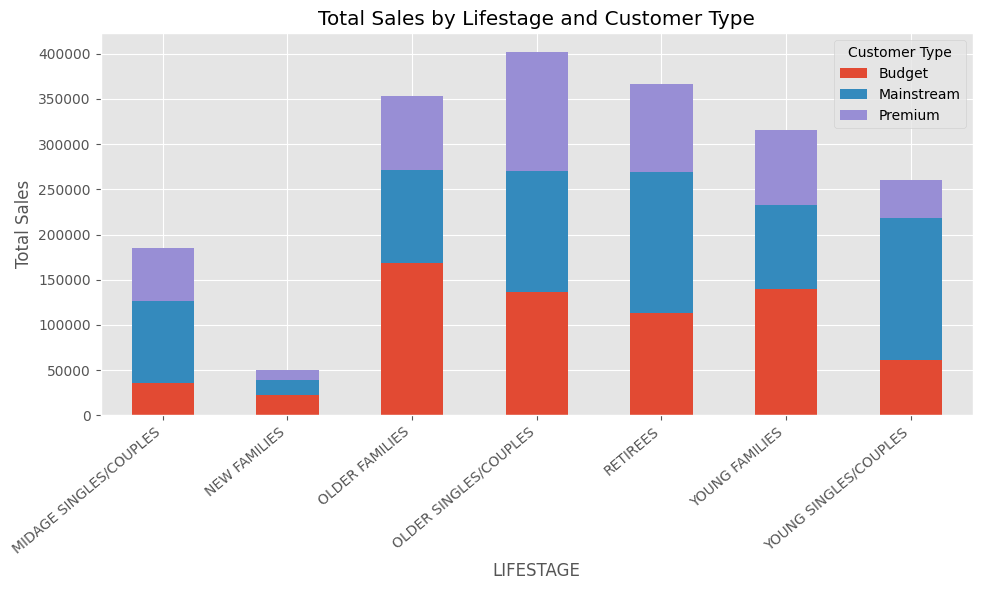

In [39]:
pivot = data.pivot_table(
    index="LIFESTAGE",
    columns="PREMIUM_CUSTOMER",
    values="TOT_SALES",
    aggfunc="sum"
)

# Plot stacked bar chart
pivot.plot(kind="bar", stacked=True, figsize=(10,6))

# Make it look professional
plt.style.use("ggplot")
plt.ylabel("Total Sales")
plt.title("Total Sales by Lifestage and Customer Type")
plt.xticks(rotation=40, ha="right")
plt.legend(title="Customer Type")
plt.tight_layout()
plt.savefig(r"images/Total Sales by Lifestage and Customer Type.png", dpi=300, bbox_inches="tight")
plt.show()